## SLU17 - Ethics & Fairness - Exercise notebook

In [73]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-dark')
plt.rcParams["figure.figsize"]=(3.5,3.5)

import hashlib
import json

from utils.utils import make_data

## Criminal justice bias

Exercise adaptated from the book [Fairness and Machine Learning by Solon Barocas, Moritz Hardt, and Arvind Narayanan](https://fairmlbook.org/pdf/fairmlbook.pdf).

Based on the ProPublica's article [Machine Bias](https://www.propublica.org/article/machine-bias-risk-assessments-in-criminal-sentencing) about a proprietary risk score algorithm, called COMPAS, used in the US.

This is the problem setting:

> Risk assessment is an important component of the criminal justice system. In the United States, judges set bail and decide pre-trial detention based on their assessment of the risk that a released defendant would fail to appear at trial or cause harm to the public.

These scores are intended to assess the risk that a defendant will re-offend, a task often called **recidivism prediction**.

We’ll use data obtained and released by ProPublica. The data shows demographic and crim-related characteristics of convicted defendants. It also shows if they reoffended within a two-year period after release from jail (the `is_recid` column). The `decile_score` and `score_text` columns show the recidivism risk prediction of the COMPAS algorithm.

In [74]:
data = make_data()
data.head()

,sex,age,age_cat,race,decile_score,priors_count,days_b_screening_arrest,c_jail_in,c_jail_out,c_charge_degree,is_recid,score_text
0,Male,69,Greater than 45,Other,1,0,-1.0,2013-08-13 06:03:42,2013-08-14 05:41:20,F,0,Low
1,Male,34,25 - 45,African-American,3,0,-1.0,2013-01-26 03:45:27,2013-02-05 05:36:53,F,1,Low
2,Male,24,Less than 25,African-American,4,4,-1.0,2013-04-13 04:58:34,2013-04-14 07:02:04,F,1,Low
5,Male,44,25 - 45,Other,1,0,0.0,2013-11-30 04:50:18,2013-12-01 12:28:56,M,0,Low
6,Male,41,25 - 45,Caucasian,6,14,-1.0,2014-02-18 05:08:24,2014-02-24 12:18:30,F,1,Medium


## Exercise 1 - Score distribution for Black and White defendants

In this exercise, we will compare the predicted `decile_score` distributions for different races. This is the score predicted by the COMPAS algorithm. High score means a high risk of reoffending. 

In the three cells below, plot the histograms of the `decile_score` for all defendants, for the Black defendants - `African-American` race, and for White defendants - `Caucasian` race. Use the `histtype='step'` option.

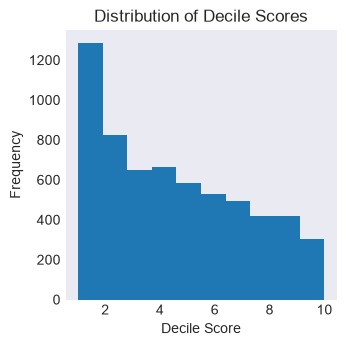

In [75]:
# Plot here the decile_score histogram for all defendants.
# YOUR CODE HERE
decile_score = data['decile_score']
plt.hist(decile_score, bins=10)
plt.xlabel('Decile Score')
plt.ylabel('Frequency')
plt.title('Distribution of Decile Scores')
plt.show()

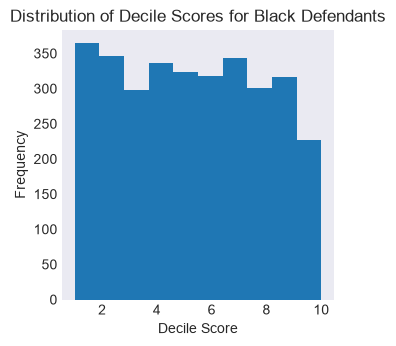

In [76]:
# Plot here the decile_score histogram for the Black defendants.
# YOUR CODE HERE
decile_score_black = data[data['race'] == 'African-American']['decile_score']
plt.hist(decile_score_black, bins=10)
plt.xlabel('Decile Score')
plt.ylabel('Frequency')
plt.title('Distribution of Decile Scores for Black Defendants')
plt.show()

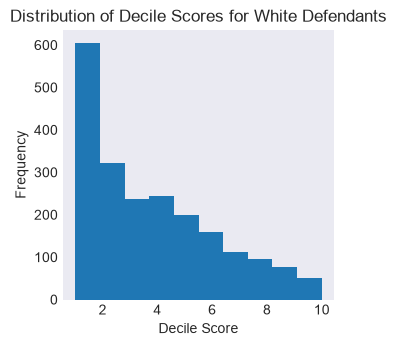

In [77]:
# Plot here the decile_score histogram for the White defendants.
# YOUR CODE HERE
decile_score_white = data[data['race'] == 'Caucasian']['decile_score']
plt.hist(decile_score_white, bins=10)
plt.xlabel('Decile Score')
plt.ylabel('Frequency')
plt.title('Distribution of Decile Scores for White Defendants')
plt.show()

### Interpretation

Based on these plots, what can you conclude from the distributions? Uncomment the correct answer.

In [78]:
# hypothesis_1 = 'The distributions of the scores are similar for the Black and White populations.'
hypothesis_1 = 'Scores for White defendants are skewed toward lower-risk categories.'
# hypothesis_1 = 'Scores for Black defendants are skewed toward lower-risk categories.'

In [79]:
assert hashlib.sha256(json.dumps(hypothesis_1).encode()).hexdigest() == \
'06e140a33dbeaa1e33267a84dde10c3edebbc01c64206f7cf30cd89839768209', 'Not correct.'

## Exercise 2 - Error rates

In this exercise, we will compare the predicted `decile_score` of people who have reoffended within a two-year period across the races. The reoffension is indicated in the column `is_recid`, 1 means reoffension.

In the three cells below, plot the histograms of the `decile_score` for all reoffenders, for the Black reoffenders - `African-American` race, and for White reoffenders - `Caucasian` race. Use the `histtype='step'` option.

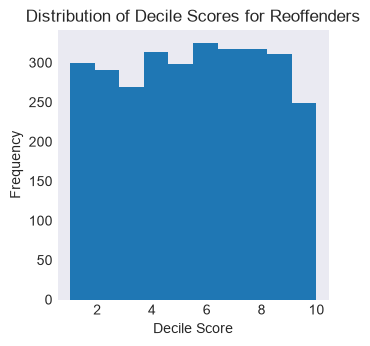

In [80]:
# Plot here the decile_score histogram for all reoffenders.
# YOUR CODE HERE
decile_score_reoffenders = data[data['is_recid'] == 1]['decile_score']
plt.hist(decile_score_reoffenders, bins=10)
plt.xlabel('Decile Score')
plt.ylabel('Frequency')
plt.title('Distribution of Decile Scores for Reoffenders')
plt.show()

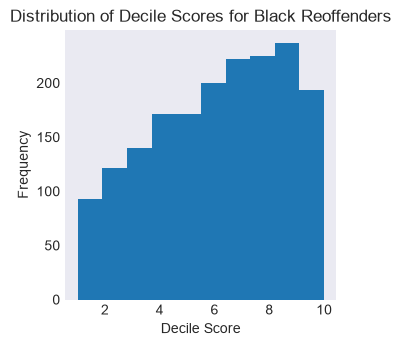

In [81]:
# Plot here the decile_score histogram for Black reoffenders.
# YOUR CODE HERE
decile_score_black_reoffenders = data[(data['race'] == 'African-American') & (data['is_recid'] == 1)]['decile_score']
plt.hist(decile_score_black_reoffenders, bins=10)
plt.xlabel('Decile Score')
plt.ylabel('Frequency')
plt.title('Distribution of Decile Scores for Black Reoffenders')
plt.show()

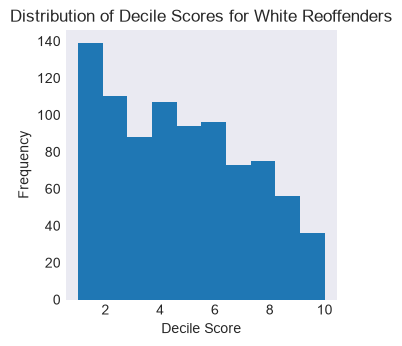

In [82]:
# Plot here the decile_score histogram for White reoffenders.
# YOUR CODE HERE
decile_score_white_reoffenders = data[(data['race'] == 'Caucasian') & (data['is_recid'] == 1)]['decile_score']
plt.hist(decile_score_white_reoffenders, bins=10)
plt.xlabel('Decile Score')
plt.ylabel('Frequency')
plt.title('Distribution of Decile Scores for White Reoffenders')
plt.show()

## Interpretation

Overall, the risk score doesn't appear to be particularly good at separating recidivists. The resulting histogram for all reoffenders resembles a uniform distribution.

Based on these plots, uncomment the correct answer. (Remember, these histograms refer to **actual recidivists**.) 

In [83]:
# hypothesis_2 = 'The distribution of recidivists scores is similar for both races groups.'
hypothesis_2 = 'Scores for White recidivists are skewed toward lower-risk categories.'
# hypothesis_2 = 'Scores for Black recidivists are skewed toward lower-risk categories.'

In [84]:
assert hashlib.sha256(json.dumps(hypothesis_2).encode()).hexdigest() == \
'b7ba150ca7b49b520bedee10410e7a92817a98aa4513e682769f618780f1489a', 'Not correct.'

## Exercise 3 - When predictions fail differently

Defendants with `decile_score` higher than 4 are classified as being at high-risk of recidivism. In this exercise, we will compare the predictions for high-risk of recidivism across the races.

In the cells below, calculate the false positive rate (FPR) for predictions of high-risk of recidivism for all people, for Black people - `African-American` race, and for White people - `Caucasian` race.

Recall that the false positive rate, also known as the probability of false alarm, is given by:

$$FPR = \frac{FP}{FP + TN} = \frac{FP}{N}$$

Where $FP$ is the number of false positives, $TN$ is the number of true negatives, and $N$ the total number of negatives. You can use the `confusion_matrix` function to calculate the true/false positives/negatives.

In [88]:
print(data.columns.tolist())
data.head()

['sex', 'age', 'age_cat', 'race', 'decile_score', 'priors_count', 'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_charge_degree', 'is_recid', 'score_text']


,sex,age,age_cat,race,decile_score,priors_count,days_b_screening_arrest,c_jail_in,c_jail_out,c_charge_degree,is_recid,score_text
0,Male,69,Greater than 45,Other,1,0,-1.0,2013-08-13 06:03:42,2013-08-14 05:41:20,F,0,Low
1,Male,34,25 - 45,African-American,3,0,-1.0,2013-01-26 03:45:27,2013-02-05 05:36:53,F,1,Low
2,Male,24,Less than 25,African-American,4,4,-1.0,2013-04-13 04:58:34,2013-04-14 07:02:04,F,1,Low
5,Male,44,25 - 45,Other,1,0,0.0,2013-11-30 04:50:18,2013-12-01 12:28:56,M,0,Low
6,Male,41,25 - 45,Caucasian,6,14,-1.0,2014-02-18 05:08:24,2014-02-24 12:18:30,F,1,Medium


In [91]:
# Calculate here the FPR for all people predicted at high-risk of recidivism.
# fpr = ...
# YOUR CODE HERE
y_pred = (data['score_text'] != 'Low').astype(int)

tn, fp, fn, tp = confusion_matrix(data['is_recid'], y_pred, labels=[0, 1]).ravel()
fpr = fp / (fp + tn)

In [94]:
# Calculate here the FPR for Black people predicted at high-risk of recidivism.
# fpr_b = ...
# YOUR CODE HERE
y_pred_black = (data[data['race'] == 'African-American']['score_text'] != 'Low').astype(int)
tn_b, fp_b, fn_b, tp_b = confusion_matrix(data[data['race'] == 'African-American']['is_recid'], y_pred_black, labels=[0, 1]).ravel()
fpr_b = fp_b / (fp_b + tn_b)

In [95]:
# Calculate here the FPR for all White predicted at high-risk of recidivism.
# fpr_w = ...
# YOUR CODE HERE
y_pred_white = (data[data['race'] == 'Caucasian']['score_text'] != 'Low').astype(int)
tn_w, fp_w, fn_w, tp_w = confusion_matrix(data[data['race'] == 'Caucasian']['is_recid'], y_pred_white, labels=[0, 1]).ravel()
fpr_w = fp_w / (fp_w + tn_w)

In [96]:
np.testing.assert_almost_equal(fpr, 0.293, decimal=3, err_msg='Calculated fpr is not correct.')
np.testing.assert_almost_equal(fpr_b, 0.414, decimal=3, err_msg='Calculated fpr_b is not correct.')
np.testing.assert_almost_equal(fpr_w, 0.216, decimal=3, err_msg='Calculated fpr_w is not correct.')

In [97]:
print(f'Overall FPR is {round(fpr,2)}, FPR for Black people is {round(fpr_b,2)}, and FPR for White people is {round(fpr_w,2)}.')

Overall FPR is 0.29, FPR for Black people is 0.41, and FPR for White people is 0.22.


Clearly, Black people are disproportionately more often falsely predicted to be at high-risk of recidivism than White people.